# Pick and Place blockstacking task resolution using Graph Neural Networks

Author: Emanuele Coletta, 2001600

Paper references:

- Lin et al. - Efficient and Interpretable Robot Manipulation  With Graph Neural Networks
- Di Felice et al. - One-Shot Imitation Learning With Graph Neural Networks for Pick-and-Place Manipulation Tasks, 

The papers consider a series of _pick and place_ tasks to be executed by a manipulator robot. Some blocks are in a given configuration in the environment and they must be picked from they current location and placed in the desired goal orientation. The scene is encoded as a graph, and a Graph Neural Network (GNN) is used to choose what block to pick and where to place it. A _PickAndPlace_ primitive executable by the robot which takes as input the object and the goal is assumed to exist, thus the work can be abstracted to work on graphs alone.

The aim of this paper is to replicate the results of the two papers in the block stacking task.
A tower of $K$ (ordered) blocks is initialized in random order at some position $(x_s, y_s)$ inside the robot workspace and must the inverted at some goal location $(x_g, y_g)$. In general $K$ blocks and $L$ goals are considered, but for blockstacking $K=L=N$ is sufficient.

A snapshot of the environment is encoded as a fully connected, undirected graph. Each node represents either an object or a goal (for the sake of simplificity, the only considered objects are blocks in this project). Each node has a feature of dimension 7:

- Categorical feature: whether it's a block or a goal (dim=2, one-hot encoded)
- Objective feature: Encodes if a block is inside a goal or if a goal is filled, respectively (dim=1, binary)
- Reachability feature: Encodes if a block/goal is reachable by the manipulator (see [Di Felice et al.]) (dim=1, binary)
- Object position (dim=3)

# Dependencies (for venv)

In [65]:
pip install -r requirements.txt

Note: you may need to restart the kernel to use updated packages.


In [66]:
import random
import torch

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')   
torch.set_default_device(device)
print(torch.get_default_device())

cuda:0


# Generate the dataset

For the blockstacking it is safe to assume that $K=L=N$. Assume fixed block size $b$.
The employed dataset is synthetically generated in the following way:

- Generate a random order for the $1,...,L$ goals
- Generate a random order for the $1,...,K$ goals by inverting the one for the goals
- Generate position of the goal tower $(x_g, y_g)$. Each goal is positioned at $(x_g, y_g, z_i)$ where $z_i = i\cdot b$ for $i=0,...,L-1$
- Generate position of the block tower $(x_s, y_s)$. Each block is positioned at $(x_s, y_s, z_i)$ where $z_i = i\cdot b$ for $i=0,...,K-1$

The state of the graph is described by two ordered arrays containing the block id and the block position and is then converted into a graph with the same procedure taken in [Lin et al.].

In [ ]:
def generate_objects(N=3, block_size=0.2, initial_tower=True):
    # 1. Generate random order for the goals
    idx_goals = [i for i in range(0, N)]
    # TODO: Better results when disabling this, why?
    # random.shuffle(idx_goals)

    # 2. Generate initial order for the blocks by inverting the order of goals
    idx_objs = idx_goals[::-1]

    # 3. Generate goals
    # https://www.generationrobots.com/media/panda-franka-emika-datasheet.pdf
    # according to the datasheet, the Franka Panda can reach in an area of 0.855 [m] around itself
    max_reach_dist = 0.7 # [m]

    # select a random (x,y) position for the goal.
    x_goal = random.random() * max_reach_dist
    y_goal = random.random() * max_reach_dist

    pos_goals = [(x_goal, y_goal, i*block_size) for i in range(0, N)]

    # Generate initial positions
    if initial_tower:
        x_obj, y_obj = x_goal, y_goal
        while (x_obj-x_goal)*(x_obj-x_goal) <= block_size*block_size:
            x_obj = random.random() * max_reach_dist
        while (y_obj-y_goal)*(y_obj-y_goal) <= block_size*block_size:
            y_obj = random.random() * max_reach_dist

        pos_objects = [(x_obj, y_obj, i*block_size) for i in range(0, N)]
    else:
        pos_objects = []

        for i in range(0, N):
            x_obj, y_obj = x_goal, y_goal
            while (x_obj-x_goal)*(x_obj-x_goal) <= block_size*block_size:
                x_obj = random.random() * max_reach_dist
            while (y_obj-y_goal)*(y_obj-y_goal) <= block_size*block_size:
                y_obj = random.random() * max_reach_dist
            pos_objects.append((x_obj, y_obj, i*block_size))

    goals = {}
    objects = {}
    for i in range(0, N):
        goals[idx_goals[i]] = pos_goals[i]
        objects[idx_objs[i]] = pos_objects[i]

    # print(f"goals (in desired order of final stacking):\n{goals}")
    # print(f"initial object positions (in order of stacking):\n{objects}")

    return objects, goals, idx_objs, idx_goals


In [68]:
# Now solve the stacking problem by taking the highest block in the objects tower (last in order)
# and putting it into the lowest available goal (first in order)

# build the state vector, ordered nodes with categorical, position and binary features, followed by ordered goals with the same features
def build_state(objects, goals):
    s = []
    N = len(objects)
    for n in range(0, N):
        # one hot encode of blocks (all nodes are either blocks or goals, all objects are blocks)
        s.append(1)
        s.append(0)

        # binary encode of whether block is in goal
        # assume that when the goal is full it's always with the correct corresponding block
        # (this is always true in the case of blockstacking, since the task is of inversion)
        full_correct = int(objects[n] == goals[n])
        s.append(full_correct)
        
        # binary encode of whether the block is reachable
        # a block is reachable if the block above it is in the right goal
        # assume that when a block is in a goal it's always in the correct corresponding goal
        # (this is always true in the case of blockstacking, since the task is of inversion)
        # TODO: a block should be reachable also if it's already in a goal, but it's the highest of the pile (but then where would you put it?).
        # Just to confuse the network. You know, for funsies
        # ultimately reachability check for a goal should be computed by checking the highest z value in a given neighborhood
        # next_full_correct = n < N-1 and int(objects[n+1] == goals[n+1])
        # s.append(not next_full_correct)

        # position of block
        for o in objects[n]: s.append(o)

    old_full = 0
    for n in range(0, N):
        # one hot encode of goals (all nodes are either blocks or goals, all objects are blocks)
        s.append(0)
        s.append(1)

        # binary encode of whether block is in goal (goal is filled)
        # assume that when the goal is full it's always with the correct corresponding block
        # (this is always true in the case of blockstacking, since the task is of inversion)
        full_correct = int(objects[n] == goals[n])
        s.append(full_correct)

        # binary encode of whether the goal is reachable
        # a goal is reachable if
        # - it's empty and it's the lowest in the pile
        # - it's empty and the one below it is full
        # assume that when the goal is full it's always with the correct corresponding block
        # (this is always true in the case of blockstacking, since the task is of inversion)
        # s.append(
        #     (not full_correct) and (n == 0 or old_full == 1)
        # )
        old_full = full_correct

        # position of block
        for o in goals[n]: s.append(o)

    return s

def build_example(N=3, block_size=0.2, initial_tower=True):
    objects, goals, idx_objs, idx_goals = generate_objects(N, block_size, initial_tower)
    
    tau = []    
    tau.append(build_state(objects, goals))

    for n in range(0, N):
        # print(f"step #{n}")
        
        o = N-1-n

        # print(f"choosing object #{idx_objs[o]} with pos {objects[idx_objs[o]]}")
        # print(f"moving object #{idx_objs[o]} to goal{goals[idx_objs[o]]}")

        objects[idx_objs[o]] = goals[idx_objs[o]] # ??? is this correct ???
        tau.append([o, o])

        # print(f"Updated object positions with goals:")
        # print(f"goals:\n{goals}")
        # print(f"current objects pos:\n{objects}")
        # print("\n")

        tau.append(build_state(objects, goals))

    # TODO (?): add the empty action to a complete graph
    # tay.append([-1, -1])
    # print(tau)
    return tau, idx_objs, idx_goals

# Observation to graph

State observation to graph transformation is executed as in [Lin et al.]

- State is converted to the feature vector of dimension (K+L, 7)
- Actions are one-hot encoded and assigned as labels for the nodes
- Adjacency matrix for fully connected graph with no self-loops

In [69]:
# Now put the demonstration in graph format, using pytorch geometric
import torch_geometric
from torch_geometric.utils import dense_to_sparse
from torch.nn import functional as F

def build_dataset(N=3, N_EXAMPLES=50):
    data_list = []
    for i in range(N_EXAMPLES):
        # print(f"Building example #{i}")
        tau, idx_objs, idx_goals = build_example(N)

        states = tau[0::2] # exclude the complete graph
        actions = tau[1::2]

        # print(len(states), states)
        # print(len(actions), actions)

        # for each step of the example, build a graph with labels
        # for blockstacking the number of steps is exactly equal to the number of blocks + 1 (encode the normal graph at the start)
        # but we ignore the full graph at the end (no action needs to be taken)
        adj = torch.ones(N+N) - torch.diag(torch.ones(N+N))
        # make edges only between an object and its intended goal
        # adj[N:, :N] = torch.zeros((N,N))
        # adj[:N, N:] = torch.eye(N)
        # convert edges to format wanted in pyg
        edge_index, _ = dense_to_sparse(adj)

        for step in range(0, len(states) -1 ):
            # print(f"Building state #{step}")
            s = states[step]
            a = actions[step]

            # torch_geometric.data.Data is a single graph
            # x is the input graph, as a matrix of dimension [node, node_features]
            x = torch.reshape(torch.tensor(s), (N*2, -1)) # N*2 considers both goals and blocks
            # print(x)

            # y is divided into two vectors, one hot encoded, probabilities for the block and the goal
            # outputs are probabilities for each index to match dimensions with the mask
            y = torch.Tensor.float(F.one_hot(torch.tensor(a), num_classes=N))
            y = torch.flatten(y)

            object_mask = x[:, 0] == 1 # for minibatch splitting during training
            G = torch_geometric.data.Data(x=x, edge_index=edge_index, y=y, object_mask=object_mask)

            # save all the graphs into a single data_list for use as a DataLoader later
            data_list.append(G)

        # print(data_list)
    return data_list

# Sanity check: draw one example

4 [Data(x=[8, 6], edge_index=[2, 56], y=[8], object_mask=[8]), Data(x=[8, 6], edge_index=[2, 56], y=[8], object_mask=[8]), Data(x=[8, 6], edge_index=[2, 56], y=[8], object_mask=[8]), Data(x=[8, 6], edge_index=[2, 56], y=[8], object_mask=[8])]


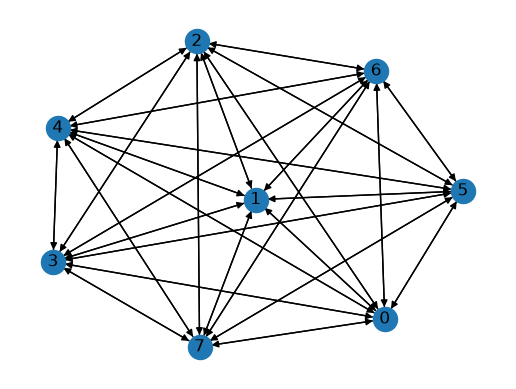

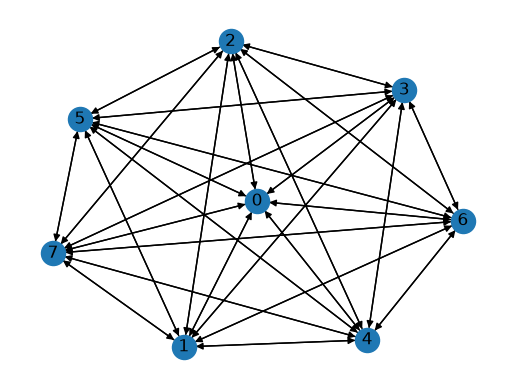

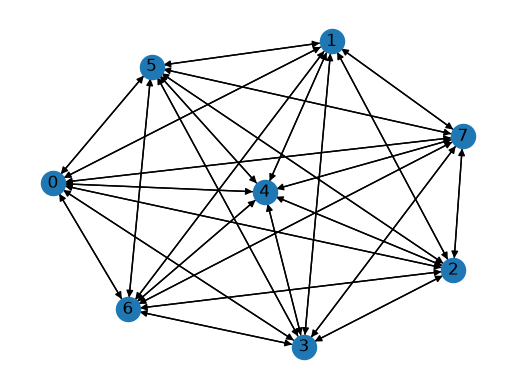

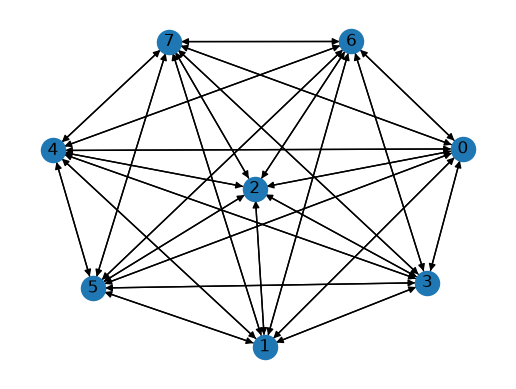

In [70]:
import networkx as nx
import matplotlib.pyplot as plt
from torch_geometric.data import Data
from torch_geometric.loader import DataLoader

example = build_dataset(N=4, N_EXAMPLES=1)

print(len(example), example)
for i in range(0, len(example)):
    fix = plt.subplots()
    g = torch_geometric.utils.to_networkx(example[i], to_undirected=False)
    nx.draw(g, with_labels=True)


# perform PCA to see if graphs clearly separate at least the input space

# Build torch_geometric dataset from examples

In [71]:
# https://pytorch-geometric.readthedocs.io/en/latest/tutorial/create_dataset.html#frequently-asked-questions
# just create a DataLoader starting from the list of example Data
from torch_geometric.data import Data
from torch_geometric.loader import DataLoader

# train_dataset = build_dataset(N=4, N_EXAMPLES=50)
train_dataset = build_dataset(N=3, N_EXAMPLES=50) + build_dataset(N=4, N_EXAMPLES=50)
# print("Training dataset: ", train_dataset)

train_loader = DataLoader(train_dataset, batch_size=16)
train2_loader = DataLoader(train_dataset, batch_size=1)
val_loader = DataLoader(build_dataset(N=4, N_EXAMPLES=10), batch_size=4)
# val_loader = DataLoader(build_dataset(N=3, N_EXAMPLES=10) + build_dataset(N=4, N_EXAMPLES=10), batch_size=1, shuffle=True)

# Build NN

[Lin et al.] compares four different strategies. In this project, 3 layers of SAGEConv with 64 hidden nodes are tested.
During training, random additive noise contained in [-0.05, 0.05] [meters] is added on the positions of each block, drawn from a uniform distribution. Empirically, this helps with generalization.

The final layer of the network is a FC layers with output dimension 1. The network performs a regression task on each node, obtaining an output that is (K+L, 1). This is further split into two $K-$ and $L-$ dimensional vectors, representing the objects and the goals respectively. The scalars associated with each node represent the probability of picking that object/goal.
A cross entropy loss is computed for each output, and optimization is performed on the sum of the two.

This particular choice is done so that the output is always (K+L, 1), independently of the number of nodes in the training dataset. Other choices considered included performing classification on the whole graph (3 GC layers + pooling + linear classifier projecting on K+L) but this would entail changing the last FC layer when the number of blocks in the scene changes.

Since the graph is fully connected and undirected, convolutional layers in PyG like GCNConv would compute the same embedding for each node (since they compute the average between neighbors of each node). This is avoided using layers with residual connections such as SAGEConv or ResGatedGraphConv

In [76]:
# https://pytorch-geometric.readthedocs.io/en/latest/modules/nn.html
# https://pytorch-geometric.readthedocs.io/en/latest/get_started/introduction.html
# https://colab.research.google.com/github/Alireza-Akhavan/graph-neural-network/blob/main/07-Graph_Classification_pyg.ipynb#scrollTo=CN3sRVuaQ88l
# https://khairulislam.github.io/GNN/pages/graph/Graph_Classification.html

# regarding the use of position (and generalization to unseen positions): https://github.com/pyg-team/pytorch_geometric/issues/3326
# regarding fully connected graphs and the use of dense layers: https://github.com/pyg-team/pytorch_geometric/issues/964

from torch.nn import Linear
from torch_geometric.nn.conv import SAGEConv, GCNConv, GATv2Conv, ResGatedGraphConv
from torch_geometric.utils import to_dense_adj, to_dense_batch, to_nested_tensor

import lightning as L
from lightning.pytorch.callbacks import Callback, EarlyStopping
from lightning.pytorch.callbacks.early_stopping import EarlyStoppingReason

class GCN(L.LightningModule):
    def __init__(self, hidden_dim=64,dropout=0.5,training_noise=True):
        super().__init__()
        self.save_hyperparameters()

        self.dropout = dropout
        self.training_noise = training_noise
        # All policies consist of 3 hidden layers, with 64 hidden units each and ReLU activation.
        # For attention policies, the number of attention heads were set to 1.
        self.conv1 = ResGatedGraphConv(6, hidden_dim)
        self.conv2 = ResGatedGraphConv(hidden_dim, hidden_dim)
        self.conv3 = ResGatedGraphConv(hidden_dim, hidden_dim)
        self.conv4 = ResGatedGraphConv(hidden_dim, hidden_dim)
        self.lin1 = Linear(hidden_dim, hidden_dim, bias=True)
        self.lin2 = Linear(hidden_dim, 1)

    def forward(self, data):
        x, edge_index, batch, object_mask = data.x, data.edge_index, data.batch, data.object_mask # batch is the index of the example

        # TODO: re-add this
        # additive measurement noise during training. Probably wrong to be added here but simpler than in batch
        if self.training and self.training_noise:
            z = torch.zeros(x.shape)
            z[:, -3:] = torch.rand((z[:, -3:].shape))*0.05
            x += z

        x = self.conv1(x, edge_index)
        x = F.relu(x)
        x = F.dropout(x, p=self.dropout, training=self.training)
        x = self.conv2(x, edge_index)
        x = F.relu(x)
        x = F.dropout(x, p=self.dropout, training=self.training)
        x = self.conv3(x, edge_index)
        x = F.relu(x)
        x = F.dropout(x, p=self.dropout, training=self.training)
        # x = self.conv4(x, edge_index)
        # x = F.relu(x)
        # x = F.dropout(x, p=self.dropout, training=self.training)
        # x = self.lin1(x)
        # x = F.relu(x)
        # x = F.dropout(x, p=self.dropout, training=self.training)

        x = self.lin2(x)

        # # The output of the GNN policy is K + L dimensional, reshaped into K and L dimensional outputs
        objects_logits = x[data.object_mask]
        objects_batch = batch[data.object_mask]


        goals_logits = x[data.object_mask]
        goals_batch = batch[data.object_mask]

        # since these outputs are interpreted as unnormalized logits, the fill value should be a large negative number to discourage the choice
        objects_dense, objects_mask = to_dense_batch(objects_logits, objects_batch, fill_value=-1e3)
        goals_dense, goals_mask = to_dense_batch(goals_logits, goals_batch, fill_value=-1e3)

        return objects_dense, goals_dense, objects_mask, goals_mask

    # TODO: check accuracy and validation during test (it was done before moving to lightning, but this is computationally faster)
    def training_step(self, batch, batch_idx):
        objects_dense, goals_dense, objects_mask, goals_mask = model(batch)

        # TODO: proper use of fill value, ignore_index
        y_obj_dense, _ = to_dense_batch(batch.y[batch.object_mask], batch.batch[batch.object_mask], fill_value=0)
        y_obj_dense = y_obj_dense.reshape(objects_dense.shape)

        y_goal_dense, _ = to_dense_batch(batch.y[~batch.object_mask], batch.batch[~batch.object_mask], fill_value=0)
        y_goal_dense = y_goal_dense.reshape(goals_dense.shape)

        # print(objects_dense, objects_dense.shape, y_obj_dense, y_obj_dense.shape)
        
        l1 = F.cross_entropy(objects_dense, y_obj_dense)
        # loss = l1
        l2 = F.cross_entropy(goals_dense, y_goal_dense)
        loss = l1+l2

        self.log('train_loss', loss, prog_bar=True, on_step=True, on_epoch=True, batch_size=batch.num_graphs)
        return loss

    def validation_step(self, batch, batch_idx):
        objects_dense, goals_dense, objects_mask, goals_mask = model(batch)

        # TODO: proper use of fill value, ignore_index
        y_obj_dense, _ = to_dense_batch(batch.y[batch.object_mask], batch.batch[batch.object_mask], fill_value=0)
        y_obj_dense = y_obj_dense.reshape(objects_dense.shape)

        y_goal_dense, _ = to_dense_batch(batch.y[~batch.object_mask], batch.batch[~batch.object_mask], fill_value=0)
        y_goal_dense = y_goal_dense.reshape(goals_dense.shape)

        # print(objects_dense, objects_dense.shape, y_obj_dense, y_obj_dense.shape)
        
        l1 = F.cross_entropy(objects_dense, y_obj_dense)
        # loss = l1
        l2 = F.cross_entropy(goals_dense, y_goal_dense)
        loss = l1+l2

        self.log('val_loss', loss, prog_bar=True, on_step=True, on_epoch=True, batch_size=batch.num_graphs)
        return loss

    def configure_optimizers(self):
        return torch.optim.Adam(self.parameters(), lr=1e-3)


model = GCN(hidden_dim=128, dropout=0.5, training_noise=True).to(device)

early_stop_callback = EarlyStopping(monitor="val_loss", min_delta=1e-8, stopping_threshold=1e-6, patience=50, verbose=False, mode="min")
trainer = L.Trainer(max_epochs=1000, callbacks=[early_stop_callback], accelerator="gpu")
trainer.fit(model, train_loader, val_loader)

# Access human-readable message
if early_stop_callback.stopping_reason_message:
    print(f"Details: {early_stop_callback.stopping_reason_message}")


def accuracy(loader):
    correct_obj = 0.
    correct_goal = 0.

    for i,batch in enumerate(loader):
        objects_dense, goals_dense, objects_mask, goals_mask = model(batch)
    
        y_obj_dense, _ = to_dense_batch(batch.y[batch.object_mask], batch.batch[batch.object_mask], fill_value=0)
        y_obj_dense = y_obj_dense.reshape(objects_dense.shape)

        y_goal_dense, _ = to_dense_batch(batch.y[~batch.object_mask], batch.batch[~batch.object_mask], fill_value=0)
        y_goal_dense = y_goal_dense.reshape(goals_dense.shape)

        # print()
        # print(objects_dense, objects_dense.shape)
        # print(batch.y)
        # print(y_obj_dense, y_obj_dense.shape)
        # # why the hell dim=1 does not work on the y
        # print(torch.argmax(objects_dense, dim=1)==torch.argmax(y_obj_dense, dim=1), torch.argmax(objects_dense, dim=1), torch.argmax(y_obj_dense, dim=1))
        # print()

        # take the argmax for the nodes in each batch
        correct_obj += (torch.argmax(objects_dense, dim=1) == torch.argmax(y_obj_dense, dim=1)).sum().item()
        correct_goal += (torch.argmax(goals_dense, dim=1) == torch.argmax(y_goal_dense, dim=1)).sum().item()

    # print(correct_obj, correct_goal)
    acc_obj = correct_obj / (i+1)
    acc_goal = correct_goal / (i+1)

    return acc_obj, acc_goal

GPU available: True (cuda), used: True
TPU available: False, using: 0 TPU cores
💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.
💡 Tip: For seamless cloud uploads and versioning, try installing [litmodels](https://pypi.org/project/litmodels/) to enable LitModelCheckpoint, which syncs automatically with the Lightning model registry.


LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]

  | Name  | Type              | Params | Mode  | FLOPs
------------------------------------------------------------
0 | conv1 | ResGatedGraphConv | 3.6 K  | train | 0    
1 | conv2 | ResGatedGraphConv | 66.0 K | train | 0    
2 | conv3 | ResGatedGraphConv | 66.0 K | train | 0    
3 | conv4 | ResGatedGraphConv | 66.0 K | train | 0    
4 | lin1  | Linear            | 16.5 K | train | 0    
5 | lin2  | Linear            | 129    | train | 0    
------------------------------------------------------------
218 K     Trainable params
0         Non-trainable params
218 K     Total params
0.873     Total estimated model params size (MB)
26        Modules in train mode
1         Modules in eval mode
0         Total Flops


Epoch 59: 100%|██████████| 6/6 [00:00<00:00, 25.57it/s, v_num=467, train_loss_step=3.790, val_loss_step=2.770, val_loss_epoch=2.770, train_loss_epoch=3.490]
Details: Monitored metric val_loss did not improve in the last 50 records. Best score: 2.772. Signaling Trainer to stop.


# Test

Compute accuracy for different block stacking tests performed on a variable number of block. The network shows good generalization capabilities on a number of blocks that has seen during training, but accuracy decreases when the number of blocks increases.

In [73]:
N_ = [3, 4, 5, 6, 7, 8, 9, 10]

model.eval().to(device)
for i in range(len(N_)):
    test_loader = DataLoader(build_dataset(N_[i], N_EXAMPLES=50), batch_size=1)
    acc_obj, acc_goal = accuracy(test_loader)
    print(f'Test Accuracy (objects/goals) - K=L={N_[i]}: {acc_obj:.4f}/{acc_goal:.4f}')

Test Accuracy (objects/goals) - K=L=3: 0.2933/0.2933
Test Accuracy (objects/goals) - K=L=4: 0.2900/0.2900
Test Accuracy (objects/goals) - K=L=5: 0.1680/0.1680
Test Accuracy (objects/goals) - K=L=6: 0.1733/0.1733
Test Accuracy (objects/goals) - K=L=7: 0.1457/0.1457
Test Accuracy (objects/goals) - K=L=8: 0.1250/0.1250
Test Accuracy (objects/goals) - K=L=9: 0.0889/0.0889
Test Accuracy (objects/goals) - K=L=10: 0.0920/0.0920


In [74]:
train_dataset = build_dataset(N=5, N_EXAMPLES=2) + build_dataset(N=6, N_EXAMPLES=2)
train_loader = DataLoader(train_dataset, batch_size=4)
model.train().to(device)
trainer.fit(model, train_loader, val_loader)

/home/emamaker/university/Università/magistrale/anno-2/semestre-1/nn/project/.venv/lib/python3.12/site-packages/lightning/pytorch/callbacks/model_checkpoint.py:881: Checkpoint directory /home/emamaker/university/Università/magistrale/anno-2/semestre-1/nn/project/lightning_logs/version_466/checkpoints exists and is not empty.
LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]

  | Name  | Type              | Params | Mode  | FLOPs
------------------------------------------------------------
0 | conv1 | ResGatedGraphConv | 3.6 K  | train | 0    
1 | conv2 | ResGatedGraphConv | 66.0 K | train | 0    
2 | conv3 | ResGatedGraphConv | 66.0 K | train | 0    
3 | conv4 | ResGatedGraphConv | 66.0 K | train | 0    
4 | lin1  | Linear            | 16.5 K | train | 0    
5 | lin2  | Linear            | 129    | train | 0    
------------------------------------------------------------
218 K     Trainable params
0         Non-trainable params
218 K     Total params
0.873     Total estimated model params siz

Epoch 52: 100%|██████████| 6/6 [00:00<00:00, 23.38it/s, v_num=466, train_loss_step=3.440, val_loss_step=2.770, val_loss_epoch=2.770, train_loss_epoch=3.350]


In [75]:
N_ = [3, 4, 5, 6, 7, 8, 9, 10]

model.eval().to(device)
for i in range(len(N_)):
    test_loader = DataLoader(build_dataset(N_[i], N_EXAMPLES=10), batch_size=1)
    acc_obj, acc_goal = accuracy(test_loader)
    print(f'Test Accuracy (objects/goals) - K=L={N_[i]}: {acc_obj:.4f}/{acc_goal:.4f}')

Test Accuracy (objects/goals) - K=L=3: 0.1667/0.1667
Test Accuracy (objects/goals) - K=L=4: 0.3500/0.3500
Test Accuracy (objects/goals) - K=L=5: 0.1600/0.1600
Test Accuracy (objects/goals) - K=L=6: 0.1333/0.1333
Test Accuracy (objects/goals) - K=L=7: 0.1714/0.1714
Test Accuracy (objects/goals) - K=L=8: 0.0750/0.0750
Test Accuracy (objects/goals) - K=L=9: 0.1111/0.1111
Test Accuracy (objects/goals) - K=L=10: 0.0900/0.0900
